In [ ]:
# Simple Stock Trading Program in Python (without using any libraries)

class Stock:
    def __init__(self, symbol, price):
        self.symbol = symbol
        self.price = price

class Portfolio:
    def __init__(self, balance):
        self.balance = balance
        self.stocks = {}

    def buy_stock(self, stock, quantity):
        cost = stock.price * quantity
        if cost > self.balance:
            print("Insufficient balance to buy the stock.")
            return
        if stock.symbol in self.stocks:
            self.stocks[stock.symbol] += quantity
        else:
            self.stocks[stock.symbol] = quantity
        self.balance -= cost
        print(f"Bought {quantity} shares of {stock.symbol} at {stock.price} each.")

    def sell_stock(self, stock, quantity):
        if stock.symbol in self.stocks:
            if self.stocks[stock.symbol] < quantity:
                print("Not enough shares to sell.")
                return
            self.stocks[stock.symbol] -= quantity
            self.balance += stock.price * quantity
            print(f"Sold {quantity} shares of {stock.symbol} at {stock.price} each.")
        else:
            print("You don't own any shares of this stock.")

    def portfolio_value(self):
        total_value = self.balance
        for symbol, quantity in self.stocks.items():
            total_value += quantity * stocks[symbol].price
        return total_value

# Sample stocks
stocks = {
    "AAPL": Stock("AAPL", 150),
    "GOOGL": Stock("GOOGL", 2700),
    "TSLA": Stock("TSLA", 800),
    # Add more stocks as needed
}

# Sample portfolio
portfolio = Portfolio(10000)  # Starting balance

# Main program loop
while True:
    print("\n1. Buy Stock\n2. Sell Stock\n3. View Portfolio\n4. Quit")
    choice = input("Enter your choice: ")

    if choice == "1":
        symbol = input("Enter stock symbol: ").upper()
        if symbol in stocks:
            quantity = int(input("Enter quantity to buy: "))
            portfolio.buy_stock(stocks[symbol], quantity)
        else:
            print("Invalid stock symbol.")

    elif choice == "2":
        symbol = input("Enter stock symbol: ").upper()
        if symbol in stocks:
            quantity = int(input("Enter quantity to sell: "))
            portfolio.sell_stock(stocks[symbol], quantity)
        else:
            print("Invalid stock symbol.")

    elif choice == "3":
        print(f"Current Balance: {portfolio.balance}")
        print("Stocks in Portfolio:")
        for symbol, quantity in portfolio.stocks.items():
            print(f"{symbol}: {quantity} shares")

    elif choice == "4":
        print("Exiting program.")
        break

    else:
        print("Invalid choice. Please try again.")



1. Buy Stock
2. Sell Stock
3. View Portfolio
4. Quit
Enter your choice: aapl
Invalid choice. Please try again.

1. Buy Stock
2. Sell Stock
3. View Portfolio
4. Quit
Enter your choice: 1
Enter stock symbol: aapl
Enter quantity to buy: 13
Bought 13 shares of AAPL at 150 each.

1. Buy Stock
2. Sell Stock
3. View Portfolio
4. Quit
Enter your choice: 4
Exiting program.


Text(0.5, 1.0, 'TATAMOTORS.NS Price Data')

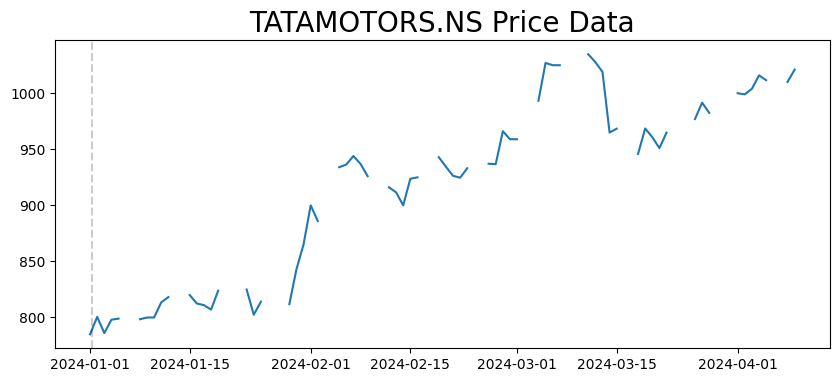

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
tickerSymbol = 'TATAMOTORS.NS'
tickerData = yf.Ticker(tickerSymbol)
tickerDf = tickerData.history(interval='1d', start='2024-1-1', end='2024-4-10')
priceData = tickerDf.Open
priceData = priceData.asfreq(pd.infer_freq(priceData.index))
priceData


plt.figure(figsize=(10,4))
plt.plot(priceData)
for year in range(priceData.index[0].year, priceData.index[-1].year+1):
    plt.axvline(datetime(year,1,1), color='k', linestyle='--', alpha=0.2)
plt.title("%s Price Data"%tickerSymbol, fontsize=20)

## Basic Buying Protocol:

### - Buy if stock increasing for $b$ consecutive days

## Basic Selling Protocols:

### - Sell if stock decreasing for $s$ consecutive days (and we've made a profit)



In [ ]:
def get_buying_selling_days(price_data, b, s):

    #get the percent change day after day
    pct_change = price_data.pct_change()[1:]

    #this function checks the buying condition
    def buying_condition(sub_series):
        return (sub_series > 0).all()

    #this function checks the selling condition
    def selling_condition(sub_series):
        return (sub_series < 0).all()

    #get all buying days in the data
    buying_days = pct_change.rolling(b).apply(buying_condition)

    #get all potential selling days in the data
    potential_selling_days = pct_change.rolling(s).apply(selling_condition)

    #return a dictionary
    return {'buying_days': buying_days, 'potential_selling_days': potential_selling_days}
info_dict = get_buying_selling_days(priceData, 1, 1)
buying_days = info_dict['buying_days']
potential_selling_days = info_dict['potential_selling_days']

#create dataframe to store information
df_stocks = pd.DataFrame(index = buying_days.index)

#populate df with buying days, possible selling days, and price
df_stocks['buying_day'] = (buying_days == 1)
df_stocks['potential_selling_day'] = (potential_selling_days == 1)
df_stocks['price'] = priceData

#only keep days that are buying or possible selling days
df_stocks = df_stocks[(df_stocks.buying_day | df_stocks.potential_selling_day)]





In [ ]:
df_stocks.head()



,buying_day,potential_selling_day,price
Date,,,
2024-01-02 00:00:00+05:30,True,False,800.500000
2024-01-03 00:00:00+05:30,False,True,786.049988
2024-01-04 00:00:00+05:30,True,False,798.000000
2024-01-05 00:00:00+05:30,True,False,799.000000
2024-01-08 00:00:00+05:30,False,True,798.400024


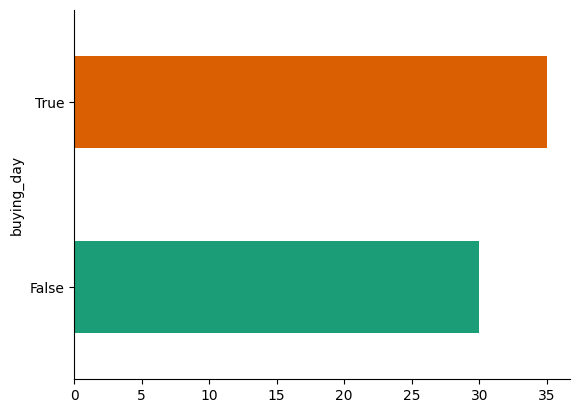

In [ ]:
# @title buying_day

from matplotlib import pyplot as plt
import seaborn as sns
df_stocks.groupby('buying_day').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
def check_cumulative_percent_change(price_data, buy_date, potential_sell_date):
    """
    This helper function will check if the cumulative percent change
    between a buying and potential selling day yields overall growth
    """

    #get the percent change day after day
    pct_change = price_data.pct_change()[1:]

    sub_series = 1 + pct_change[buy_date + timedelta(hours=1): potential_sell_date]

    return sub_series.product() > 1

In [ ]:
def get_investing_result(df_stocks, starting_funds, verbose=False):

    #get a copy of price data
    price_data = df_stocks.price

    #at start, not holding any shares
    holding = False

    #init vars
    current_funds = starting_funds
    current_shares = 0
    last_buy_date = None

    #init dict of buying and selling dates
    events_list = []

    #for each buying day and potential selling day...
    for date,data in df_stocks.iterrows():

        #if not currently holding shares, and this is a buying day...
        if (not holding) and data.buying_day:

            #calculate the number of shares we can buy
            num_shares_to_buy = int(current_funds / data.price)

            #update number of shares
            current_shares += num_shares_to_buy

            #decrease current funds
            current_funds -= num_shares_to_buy * data.price

            #set last buy date
            last_buy_date = date
            events_list.append(('b', date))

            #we are now holding shares
            holding = True

            if verbose:
                print('Bought %s shares at $%s on %s totaling $%s'%(num_shares_to_buy, data.price, date.date(), round(num_shares_to_buy*data.price,2)))

        #if you are holding shares, and this is a potential selling day...
        elif holding and data.potential_selling_day:

            #check to make sure we're making a profit
            if check_cumulative_percent_change(price_data, last_buy_date, date):
                #add to our current funds
                current_funds += current_shares * data.price

                if verbose:
                    print('Sold %s shares at $%s on %s totaling $%s'%(current_shares, data.price, date.date(), round(num_shares_to_buy*data.price,2)))
                    print('--------------------------------------')

                #reset current shares
                current_shares = 0

                #we are no longer holding shares
                holding = False

                events_list.append(('s', date))

    #get the stock price at the end of the time span
    final_stock_price = price_data[-1]

    #get the final total value of all assets (funds + stock value)
    final_value = current_funds + final_stock_price * current_shares

    #return the percent change in value
    return round((final_value - starting_funds) / starting_funds,2), events_list

In [ ]:
percent_change, events_list = get_investing_result(df_stocks, 10000, True)

Bought 12 shares at $800.5 on 2024-01-02 totaling $9606.0
Sold 12 shares at $812.4500122070312 on 2024-01-16 totaling $9749.4
--------------------------------------
Bought 12 shares at $823.8499755859375 on 2024-01-19 totaling $9886.2
Sold 12 shares at $886.0 on 2024-02-02 totaling $10632.0
--------------------------------------
Bought 11 shares at $934.0 on 2024-02-05 totaling $10274.0
Sold 11 shares at $937.0 on 2024-02-08 totaling $10307.0
--------------------------------------
Bought 11 shares at $923.7000122070312 on 2024-02-15 totaling $10160.7
Sold 11 shares at $934.4500122070312 on 2024-02-20 totaling $10278.95
--------------------------------------
Bought 11 shares at $933.0999755859375 on 2024-02-23 totaling $10264.1
Sold 11 shares at $936.75 on 2024-02-27 totaling $10304.25
--------------------------------------
Bought 11 shares at $966.1500244140625 on 2024-02-28 totaling $10627.65
Sold 11 shares at $1025.0 on 2024-03-06 totaling $11275.0
-----------------------------------

In [ ]:
print(percent_change)

0.16


(745.0, 1086.0)

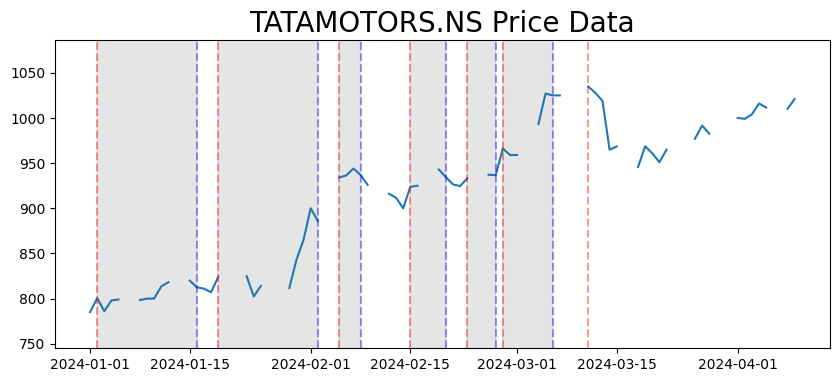

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(priceData)

y_lims = (int(priceData.min()*.95), int(priceData.max()*1.05))
shaded_y_lims = int(priceData.min()*.5), int(priceData.max()*1.5)

for idx, event in enumerate(events_list):
    color = 'red' if event[0] == 'b' else 'blue'
    plt.axvline(event[1], color=color, linestyle='--', alpha=0.4)
    if event[0] == 's':
        plt.fill_betweenx(range(*shaded_y_lims),
                          event[1], events_list[idx-1][1], color='k', alpha=0.1)

plt.title("%s Price Data"%tickerSymbol, fontsize=20)
plt.ylim(*y_lims)